In [29]:
from data_loader import load_dataset_cleaned
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

df = load_dataset_cleaned()
eda = df.copy()
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


income
<=50K    37128
>50K     11685
Name: count, dtype: int64


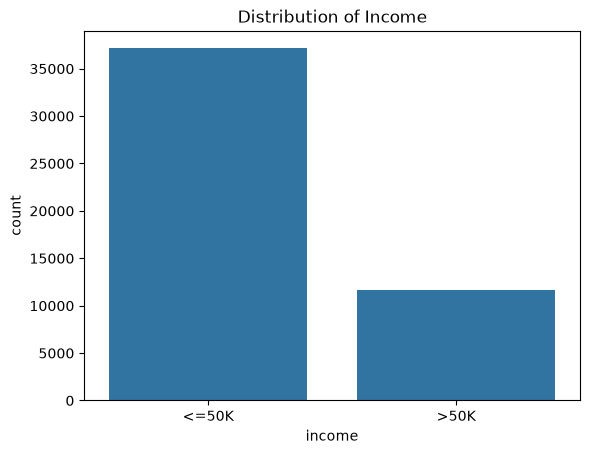

In [30]:
print(eda["income"].value_counts())

sns.countplot(data=eda, x='income')
plt.title('Distribution of Income')
plt.show()

Record with an income lesser or equal 50k are more than 3 times the record with more than 50k of income

In [31]:
eda["high_income"] = (
    eda["income"].astype("string").str.strip().str.rstrip(".") == ">50K"
).astype(int)

In [32]:
eda["age_group"] = pd.cut(
    eda["age"],
    bins=[16, 25, 35, 45, 55, 65, np.inf],
    labels=["17-25", "26-35", "36-45",
            "46-55", "56-65", "65+"]
)

age_target = (
    eda.groupby("age_group", observed=True)
    .agg(
        records=("high_income", "size"),
        income_rate=("high_income", "mean")
    )
)

age_target["income_rate"] *= 100

display(age_target)

,records,income_rate
age_group,,
17-25,9614,1.757853
26-35,12713,18.713128
36-45,11947,34.560978
46-55,8292,39.254703
56-65,4445,31.406074
65+,1802,19.811321


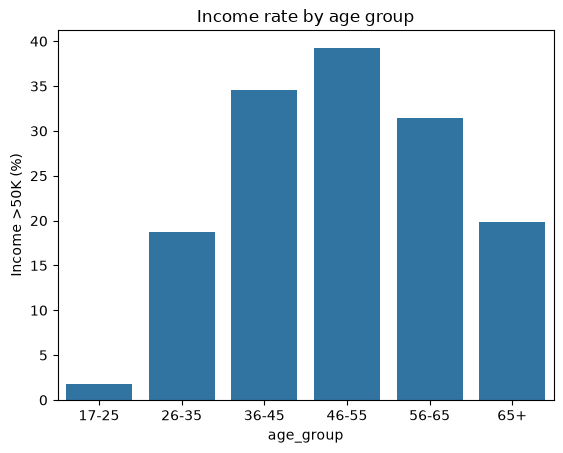

In [33]:
sns.barplot(
    data=age_target.reset_index(),
    x="age_group",
    y="income_rate"
)

plt.ylabel("Income >50K (%)")
plt.title("Income rate by age group")
plt.show()

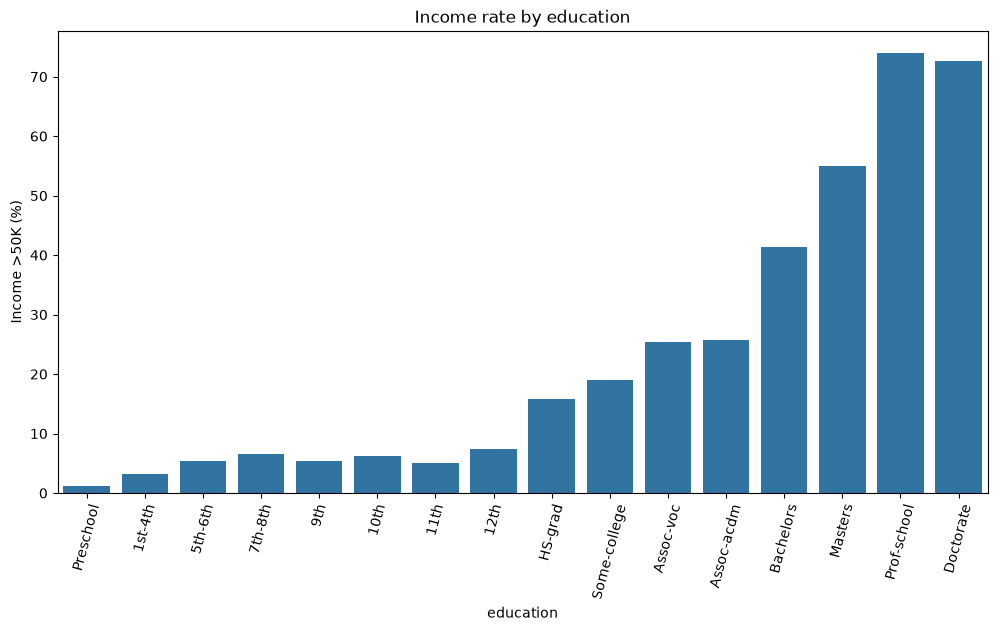

In [34]:
education_target = (
    eda.groupby(
        ["education", "education_num"],
        observed=True
    )
    .agg(
        records=("high_income", "size"),
        income_rate=("high_income", "mean")
    )
    .reset_index()
    .sort_values("education_num")
)

education_target["income_rate"] *= 100

plt.figure(figsize=(12, 6))

sns.barplot(
    data=education_target,
    x="education",
    y="income_rate",
    order=education_target["education"]
)

plt.xticks(rotation=75)
plt.ylabel("Income >50K (%)")
plt.title("Income rate by education")
plt.show()

The graph shows a correlation, the higher the education the higher the probability the income will be high.

In [35]:
occupation_target = (
    eda.groupby("occupation", dropna=False)
    .agg(
        records=("high_income", "size"),
        income_rate=("high_income", "mean")
    )
)

occupation_target["income_rate"] *= 100

occupation_target = occupation_target.sort_values(
    "income_rate",
    ascending=False
)

display(occupation_target)

,records,income_rate
occupation,,
Exec-managerial,6084,47.797502
Prof-specialty,6167,45.127290
Armed-Forces,15,33.333333
Protective-serv,983,31.332655
Tech-support,1445,29.065744
Sales,5504,26.798692
Craft-repair,6107,22.646144
Transport-moving,2355,20.424628
Adm-clerical,5608,13.694722


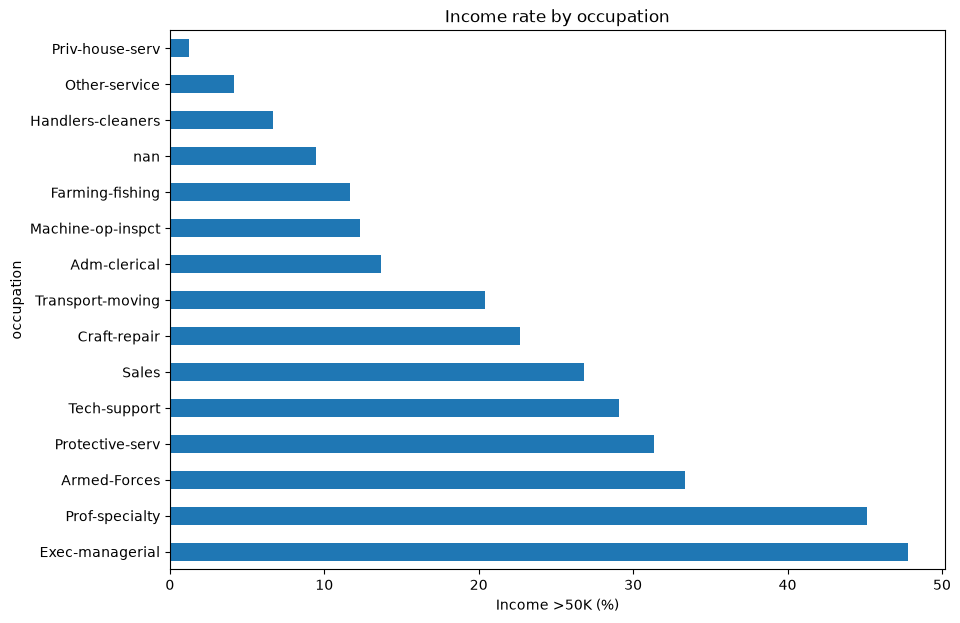

In [36]:
occupation_target["income_rate"].plot(
    kind="barh",
    figsize=(10, 7)
)

plt.xlabel("Income >50K (%)")
plt.title("Income rate by occupation")
plt.show()

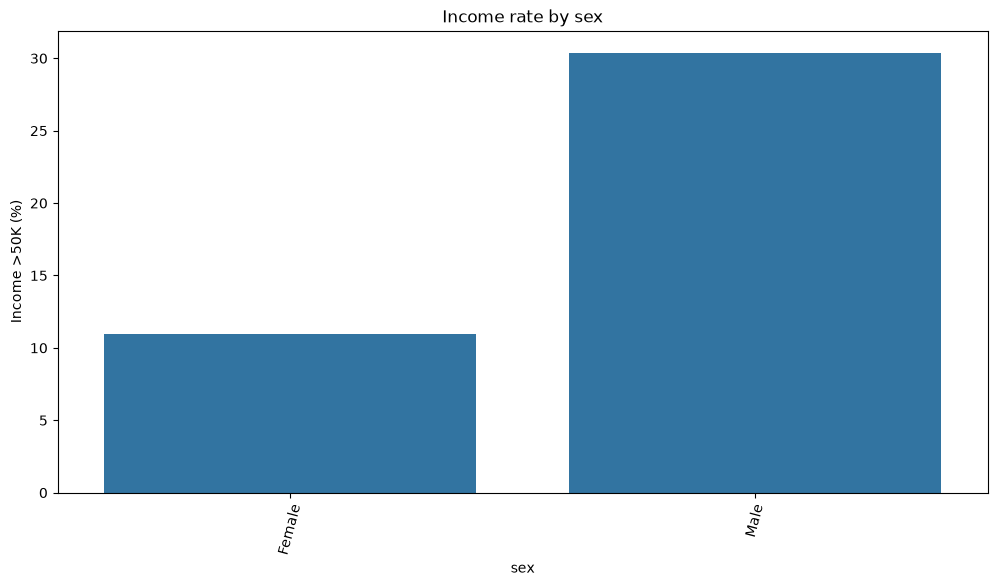

In [37]:
sex_target = (
    eda.groupby(
        ["sex"],
        observed=True
    )
    .agg(
        records=("high_income", "size"),
        income_rate=("high_income", "mean")
    )
    .reset_index()
    .sort_values("sex")
)

sex_target["income_rate"] *= 100

plt.figure(figsize=(12, 6))

sns.barplot(
    data=sex_target,
    x="sex",
    y="income_rate",
    order=sex_target["sex"]
)

plt.xticks(rotation=75)
plt.ylabel("Income >50K (%)")
plt.title("Income rate by sex")
plt.show()

The graph shows a disparity in income dictated by the gender.

## Multivariate analysis on age and education

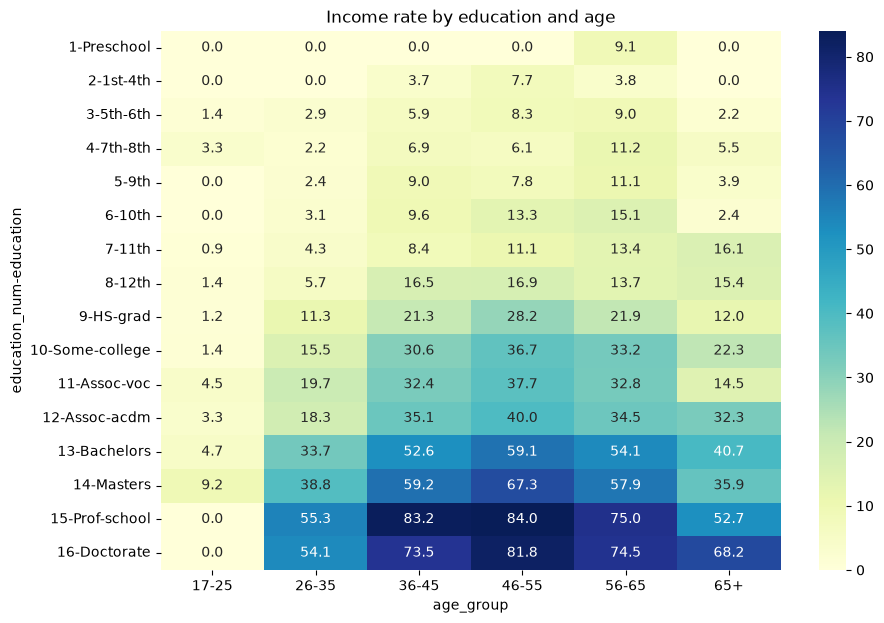

In [38]:
heatmap_data = eda.pivot_table(
    values="high_income",
    index=["education_num","education"],
    columns="age_group",
    aggfunc="mean",
    observed=True
) * 100

plt.figure(figsize=(10, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Income rate by education and age")
plt.show()

The study indicates the income with the same degree varies with age.

## Comparing weithed and unweighted income rate

In [40]:
def compare_weighted(data, group_col):
    temp = data[[group_col, "high_income", "fnlwgt"]].dropna(
        subset=["high_income", "fnlwgt"]
    ).copy()

    temp["weighted_positive"] = (
        temp["high_income"] * temp["fnlwgt"]
    )

    result = temp.groupby(
        group_col,
        observed=True,
        dropna=False
    ).agg(
        records=("high_income", "size"),
        unweighted_rate=("high_income", "mean"),
        total_weight=("fnlwgt", "sum"),
        positive_weight=("weighted_positive", "sum")
    )

    result["weighted_rate"] = (
        result["positive_weight"] /
        result["total_weight"] * 100
    )

    result["unweighted_rate"] *= 100

    return result

weighted_age = compare_weighted(eda, "age_group")

display(weighted_age[
    ["records", "unweighted_rate", "weighted_rate"]
])

,records,unweighted_rate,weighted_rate
age_group,,,
17-25,9614,1.757853,1.851272
26-35,12713,18.713128,18.746194
36-45,11947,34.560978,35.104177
46-55,8292,39.254703,39.917632
56-65,4445,31.406074,31.768981
65+,1802,19.811321,19.633793


The income rate does not vary significantly when weighted 